<h1>Практическая работа: "Знакомство с алгоритма k-ближайших соседей (kNN)"</h1>

__K-ближайший сосед с использованием scikit-learn__

__Задача обучения__  
Набор данных "Ирисы Фишера". Нужно определить к какому классу принадлежит неопознанное растение ириса,
Классификация осуществляется на основе размеров чашелистиков и лепестков.

In [34]:
#Импорт необходимых библиотек
import warnings

warnings.filterwarnings('ignore')

In [35]:
#!pip install mlxtend

In [36]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import itertools
from mlxtend.plotting import plot_decision_regions

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_curve, roc_auc_score

%matplotlib inline
plt.rcParams["figure.figsize"] = (10,5)

__Изучение набора данных__  
Набор данных "Ирисы Фишера" — это популярный многомерный набор данных, часто используемый в машинном обучении. 
Набор данных состоит из 150 образцов, равномерно распределенных по трем видам ирисов: 
ирис сетозный, ирис виргинский, ирис разноцветный. 
Каждый образец состоит из четырех атрибутов: длины и ширины чашелистиков и лепестков в сантиметрах.
Задача состоит в том, чтобы предсказать, к какому классу принадлежит неопознанное растение ириса,
основываясь на размерах чашелистиков и лепестков.

In [37]:
dataset = datasets.load_iris()
df = pd.DataFrame(data=np.c_[dataset['data'], dataset['target']],
                    columns=dataset['feature_names'] + ['target'])

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0


__Описания наборов данных__

In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    float64
dtypes: float64(5)
memory usage: 6.0 KB


In [39]:
dict(zip( dataset.target_names, df['target'].unique()))

{np.str_('setosa'): np.float64(0.0),
 np.str_('versicolor'): np.float64(1.0),
 np.str_('virginica'): np.float64(2.0)}

In [40]:
temp_df = df.copy()

temp_df['target'] = temp_df['target'].map(dict(zip( temp_df['target'].unique(), dataset.target_names)))

<Axes: xlabel='target', ylabel='count'>

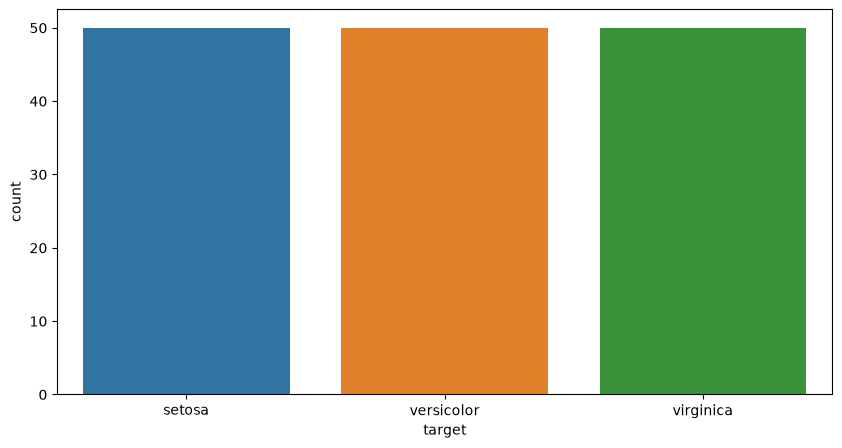

In [41]:
sns.countplot(x='target', hue='target', data=temp_df)

Из графика выше мы видим, что наши данные идеально сбалансированы.

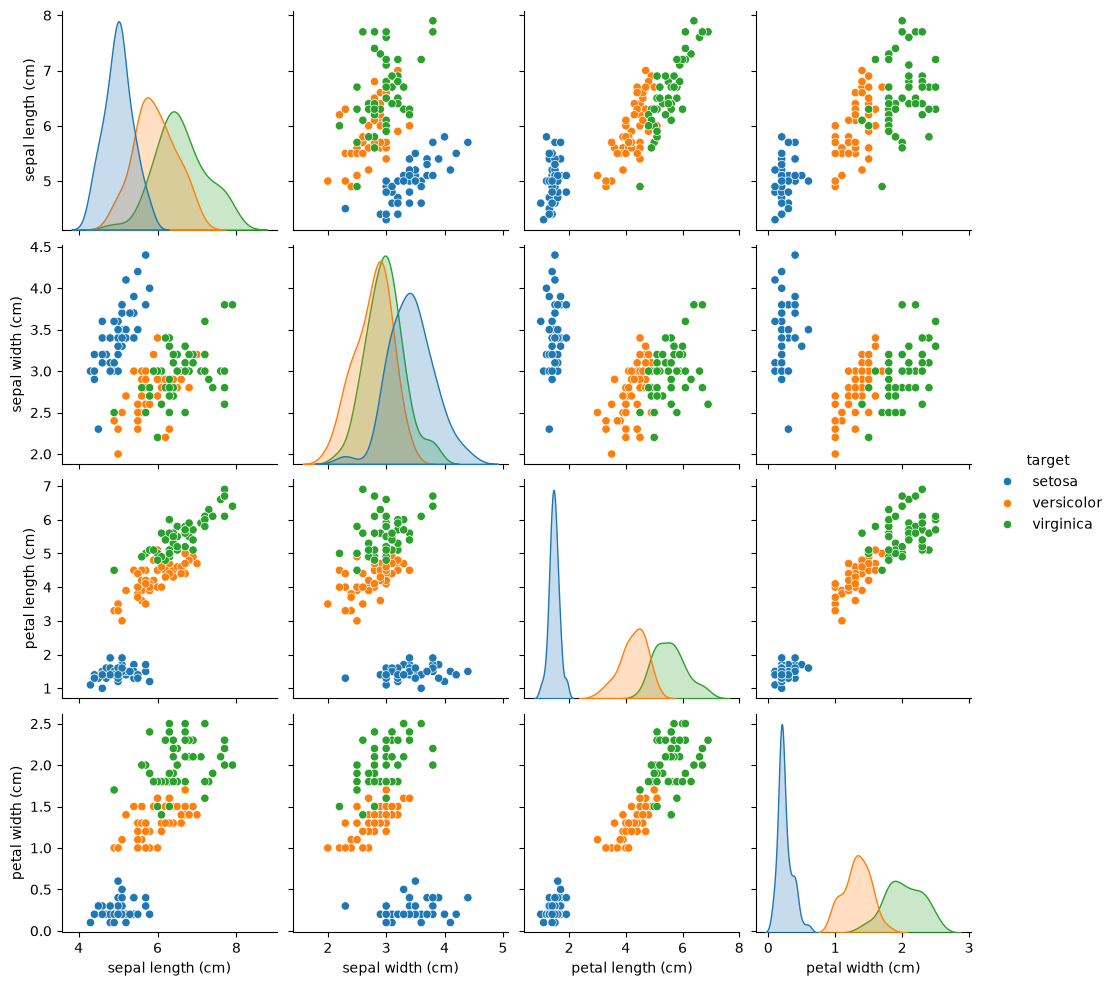

In [42]:
sns.pairplot(temp_df, hue='target')

На графике выше мы можем видеть взаимосвязь между каждой функцией. Мы можем увидеть, являются ли признаки разделимыми или нет.

<h2>Синтетический набор данных KNN</h2>

In [43]:
from IPython.display import display, Javascript, HTML
from IPython.display import IFrame
display(HTML('build.html'))

<h2>Модели КNN</h2>

Теперь мы построим разные модели для разных пар признаков, чтобы увидеть, насколько полезны признаки для определения их вида.

In [44]:
# Helper functions

def display_confusion_matrix(
    matrix, labels=None,
    title="Confusion Matrix",
    xlabel="Predicted",
    ylabel="Actual",
    figsize=None,
    cmap="Blues",
    vmin=None,
    vmax=None,
):
    """Display a confusion matrix. 
  
    Display the confusion matrix found in matrix using matplotlib.
  
    Parameters
    ----------
    matrix : array-like
        Confusion matrix to display, shape [n_classes, n_classes].
    
    labels : array-like, default=None
        Class labels for the confusion matrix, shape [n_classes].
        
    title : str, default='Confusion Matrix'
        Title displayed on the confusion matrix.
    
    xlabel : str, default='Predicted'
        x-label displayed on the confusion matrix.
    
    ylabel : str, default='Actual'
        y-label displayed on the confusion matrix.
    
    figsize : array-like
        Array-like, length two, specifying the figsize of the plot.
        
    cmap : matplotib.colors.Colormap or str, default='Blues'
        Colormap used when displaying the entries of the confusion matrix.
        
    vmin,vmax : int or float
        *vmin* and *vmax* define the data range that the colormap covers.
    """
    
    if labels is None:
        labels = [""]*len(matrix)
    if vmin is None:
        vmin = 0.
    if vmax is None:
        vmax = np.sum(matrix[0])
    t_hold = (vmax-vmin) / 2.
    fig,ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix, cmap=cmap)
    for row,col in itertools.product(range(len(labels)), range(len(labels))):
        color = "white" if matrix[row,col] > t_hold else "black"
        ax.text(col, row, matrix[row, col], horizontalalignment="center", color=color)
    tick_marks = np.arange(len(labels))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels)
    plt.show()

<h2>Модель 1 (длина чашелистика и ширина чашелистика)</h2>  
Для начала мы собираемся построить модель KNN с длиной и шириной чашелистика. Мы обучим модель этим двум функциям и оценим ее эффективность с помощью карты классификации и матрицы путаницы.

In [45]:
X = df[['sepal length (cm)', 'sepal width (cm)']]
y_true = df['target']
model_1 = KNeighborsClassifier()
model_1.fit(X, y_true)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](3,)","[0.,1.,2.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


<h3>Оценка модели 1</h3>

<Axes: >

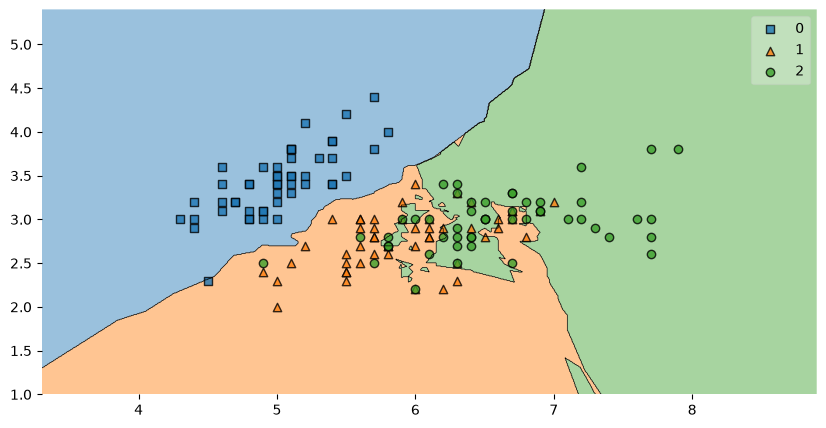

In [46]:
plot_decision_regions(X.values, y_true.values.astype(np.int64), model_1)

[[49  1  0]
 [ 0 38 12]
 [ 0 12 38]]


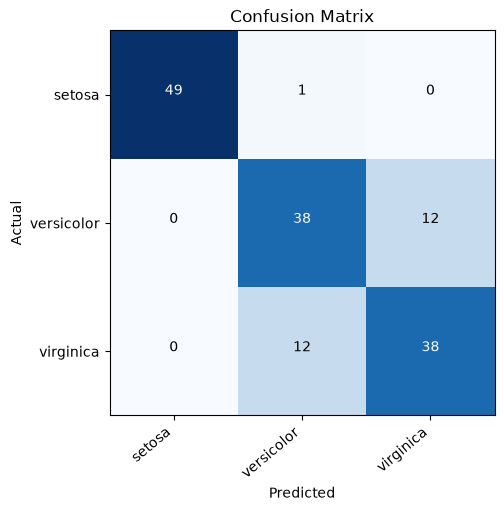

In [47]:
y_hat = model_1.predict(X)
labels = df["target"].unique()

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

<h1>Модель 2 (длина и ширина лепестка)</h1>  
Теперь для нашей второй модели мы собираемся использовать функции длины и ширины лепестка в качестве входных данных.

In [48]:
X = df[['petal length (cm)', 'petal width (cm)']]

model_2 = KNeighborsClassifier()
model_2.fit(X, y_true)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](3,)","[0.,1.,2.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


__Model 2 Evaluation__

<Axes: >

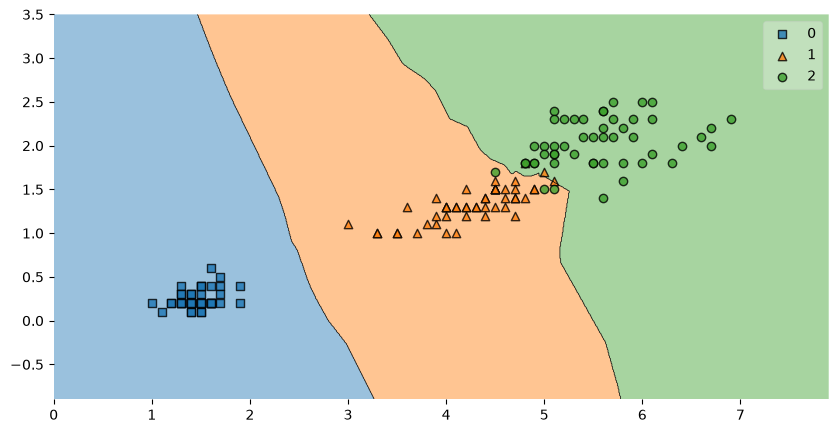

In [49]:
plot_decision_regions(X.values, y_true.values.astype(np.int64), model_2)

[[50  0  0]
 [ 0 47  3]
 [ 0  3 47]]


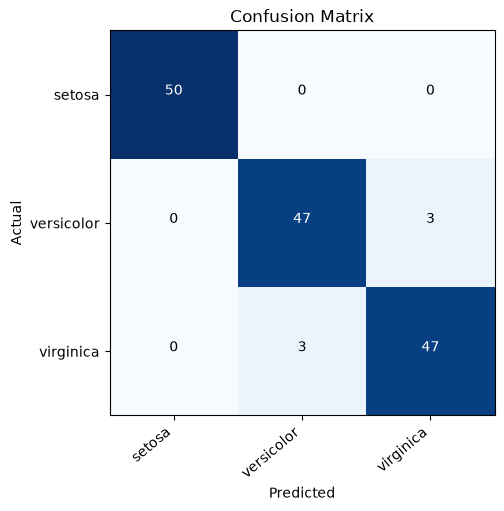

In [50]:
y_hat = model_2.predict(X)

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

<h1>Модель 3 (все функции)</h1>  
Теперь что касается нашей окончательной модели, мы собираемся использовать все доступные функции и обучить нашу модель KNN.

In [51]:
X = df.drop(['target'], axis=1)

In [52]:
model_3 = KNeighborsClassifier()
model_3.fit(X, y_true)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](3,)","[0.,1.,2.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


__Модель 3 Оценка__

[[50  0  0]
 [ 0 47  3]
 [ 0  2 48]]


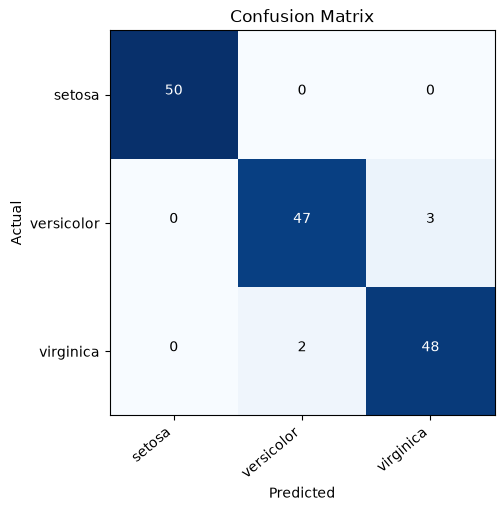

In [53]:
y_hat = model_3.predict(X)

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

Вы можете видеть, что окончательная модель со всеми функциями работает лучше, чем все другие модели. Меньше ошибочной классификации.

Однако до сих пор мы обучали и оценивали наши модели в одном и том же наборе данных. Использование одних и тех же данных для обучения и оценки не рекомендуется.

__Модель на разделенном наборе данных__

Здесь мы разделим наш набор данных на обучающий и тестовый набор и обучим нашу модель в обучающем наборе. Позже во время оценки мы собираемся использовать наш изолированный набор тестов.

In [54]:
X = df.drop(['target'], axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3)

In [55]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](3,)","[0.,1.,2.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [56]:
preds = knn.predict(X_test)

print(classification_report(preds, y_test))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00        15
         1.0       0.93      0.93      0.93        15
         2.0       0.93      0.93      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



[[15  0  0]
 [ 0 14  1]
 [ 0  1 14]]


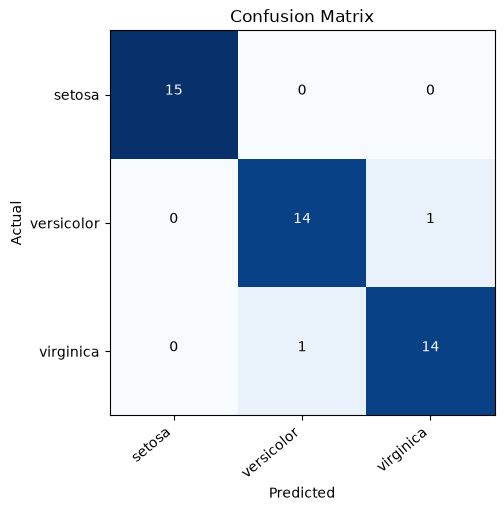

In [57]:
matrix = confusion_matrix(y_test, preds, labels=y.unique(), normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

Выше вы можете видеть, что точность нашего набора тестовых данных составляет 98%.

Из матрицы путаницы мы также видим, что у нас очень низкий уровень ошибок классификации.

Для наших вышеупомянутых моделей мы также можем использовать данные обучения и тестирования отдельно, оценивать эти модели, а затем выбирать лучшую модель.

<h1>Задание</h1>  
С помощью метода kNN определить качество красного вина. Использовать датасет winequality-red.csv, который находится в папке data.
Для этого разделить набор данных на обучающий и тестовый набор и обучим нашу модель в обучающем наборе. 
Построить матрицу путаници. Сделать выводы по полученным результатам. 

In [58]:
wine_data = pd.read_csv('winequality-red.csv', sep=";")

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

print(wine_data)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00            1.90      0.076   
1               7.8             0.880         0.00            2.60      0.098   
2               7.8             0.760         0.04            2.30      0.092   
3              11.2             0.280         0.56            1.90      0.075   
4               7.4             0.700         0.00            1.90      0.076   
5               7.4             0.660         0.00            1.80      0.075   
6               7.9             0.600         0.06            1.60      0.069   
7               7.3             0.650         0.00            1.20      0.065   
8               7.8             0.580         0.02            2.00      0.073   
9               7.5             0.500         0.36            6.10      0.071   
10              6.7             0.580         0.08            1.80      0.097   
11              7.5         

In [59]:
print(f"Dataset size: l = {len(wine_data)} objects")
print(f"Number of features: n = {wine_data.shape[1] - 1}")

Dataset size: l = 1599 objects
Number of features: n = 11


Бинарная метка:

quality >= 6  ->  1  ("Хорошее")

quality <= 5  -> -1  ("Не качественное")

In [60]:
wine_data['label'] = np.where(wine_data['quality'] >= 6, 1, -1)

print("Классы:")
print(wine_data['label'].value_counts())
print(f"\nДоля хороших вин: {(wine_data['label'] == 1).mean()*100:.2f}%")

Классы:
label
 1    855
-1    744
Name: count, dtype: int64

Доля хороших вин: 53.47%


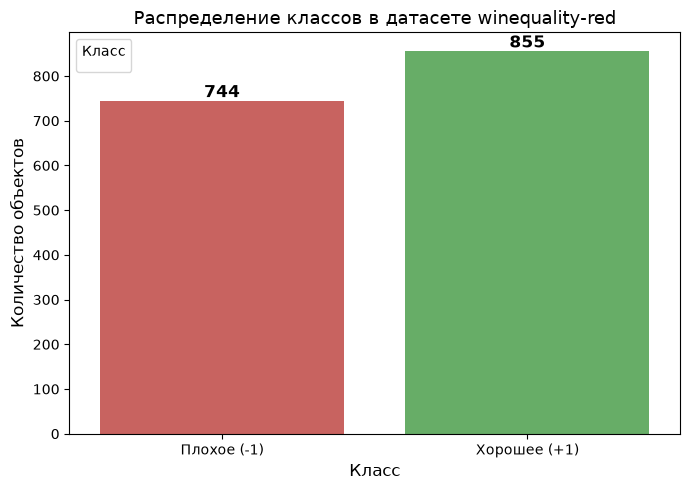

In [61]:
temp_df = wine_data.copy()
temp_df['label_name'] = temp_df['label'].map({-1: 'Плохое (-1)', 1: 'Хорошее (+1)'})

plt.figure(figsize=(7, 5))
ax = sns.countplot(x='label_name', hue='label_name', data=temp_df,
                   order=['Плохое (-1)', 'Хорошее (+1)'],
                   palette={'Плохое (-1)': '#d9534f', 'Хорошее (+1)': '#5cb85c'})
plt.title('Распределение классов в датасете winequality-red', fontsize=13)
plt.xlabel('Класс', fontsize=12)
plt.ylabel('Количество объектов', fontsize=12)
plt.legend(title='Класс')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [62]:
feature_cols = [c for c in wine_data.columns if c not in ('quality', 'label')]

X = wine_data[feature_cols].values.astype(np.float64)
y = wine_data['label'].values.astype(np.int64)

print(f"Размер X: {X.shape}")
print(f"Размер y: {y.shape}")
print(f"Признаки: {feature_cols}")

Размер X: (1599, 11)
Размер y: (1599,)
Признаки: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y
)

print(f"Обучающая выборка: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Тестовая выборка:  X_test  = {X_test.shape},  y_test  = {y_test.shape}")

print("\nРаспределение классов в обучающей выборке:")
print(pd.Series(y_train).value_counts())
print("\nРаспределение классов в тестовой выборке:")
print(pd.Series(y_test).value_counts())

Обучающая выборка: X_train = (1119, 11), y_train = (1119,)
Тестовая выборка:  X_test  = (480, 11),  y_test  = (480,)

Распределение классов в обучающей выборке:
 1    598
-1    521
Name: count, dtype: int64

Распределение классов в тестовой выборке:
 1    257
-1    223
Name: count, dtype: int64


Масштабирование признаков 

kNN — метрический алгоритм, основанный на расстояниях

In [64]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("После масштабирования:")
print(f"  X_train_scaled mean ≈ {X_train_scaled.mean():.6f}, std ≈ {X_train_scaled.std():.6f}")

После масштабирования:
  X_train_scaled mean ≈ -0.000000, std ≈ 1.000000


Обучение модели kNN

In [65]:
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[-1, 1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


Предсказание и метрики качества

In [ ]:
y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])
TN, FP, FN, TP = cm.ravel()
specificity = TN / (TN + FP)

print("\nQuality metrics:")
print(f"  Accuracy    = {accuracy:.4f}")
print(f"  Precision   = {precision:.4f}")
print(f"  Recall      = {recall:.4f}")
print(f"  F1-score    = {f1:.4f}")
print(f"  Specificity = {specificity:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Плохое (-1)', 'Хорошее (+1)']))


Quality metrics:
  Accuracy    = 0.7271
  Precision   = 0.7266
  Recall      = 0.7860
  F1-score    = 0.7551
  Specificity = 0.6592

Classification Report:
              precision    recall  f1-score   support

 Плохое (-1)       0.73      0.66      0.69       223
Хорошее (+1)       0.73      0.79      0.76       257

    accuracy                           0.73       480
   macro avg       0.73      0.72      0.72       480
weighted avg       0.73      0.73      0.73       480



Матрица ошибок:
[[147  76]
 [ 55 202]]


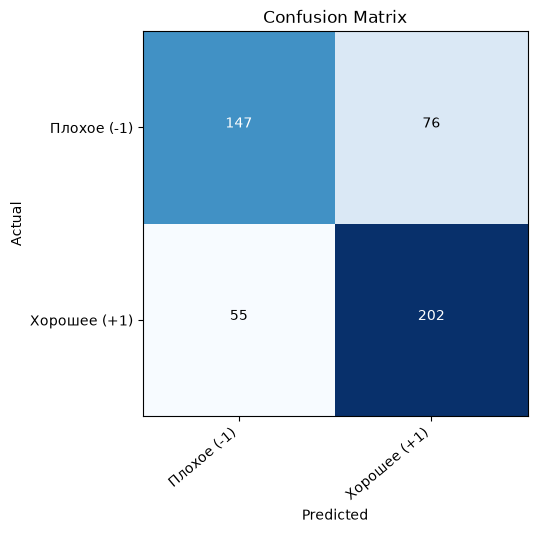

In [67]:
def display_confusion_matrix(
    matrix, labels=None,
    title="Confusion Matrix",
    xlabel="Predicted",
    ylabel="Actual",
    figsize=None,
    cmap="Blues",
    vmin=None,
    vmax=None,
):
    if labels is None:
        labels = [""] * len(matrix)
    if vmin is None:
        vmin = 0.
    if vmax is None:
        vmax = np.sum(matrix[0])
    t_hold = (vmax - vmin) / 2.
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix, cmap=cmap)
    for row, col in itertools.product(range(len(labels)), range(len(labels))):
        color = "white" if matrix[row, col] > t_hold else "black"
        ax.text(col, row, matrix[row, col], horizontalalignment="center", color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels)
    plt.show()


print("Матрица ошибок:")
print(cm)
display_confusion_matrix(cm, ['Плохое (-1)', 'Хорошее (+1)'])

Проверка на конкретной бутылке

In [68]:
def predict_wine_knn(x, model=knn, scaler=scaler):
    x_arr = np.array(x, dtype=np.float64).reshape(1, -1)
    x_scaled = scaler.transform(x_arr)
    pred = model.predict(x_scaled)[0]
    proba = model.predict_proba(x_scaled)[0]
    label = "Хорошее" if pred == 1 else "Плохое"
    print(f"Бутылка: {list(x)}")
    print(f"  Предсказание: {label}")
    print(f"  P(Плохое) = {proba[0]:.4f}, P(Хорошее) = {proba[1]:.4f}")
    print()
    return label

predict_wine_knn([7.4, 0.7, 0.0, 1.9, 0.076, 11.0, 34.0, 0.9978, 3.51, 0.56, 9.4])

predict_wine_knn([7.3, 0.65, 0.0, 1.2, 0.065, 15.0, 21.0, 0.9946, 3.39, 0.47, 10.0])

Бутылка: [7.4, 0.7, 0.0, 1.9, 0.076, 11.0, 34.0, 0.9978, 3.51, 0.56, 9.4]
  Предсказание: Плохое
  P(Плохое) = 1.0000, P(Хорошее) = 0.0000

Бутылка: [7.3, 0.65, 0.0, 1.2, 0.065, 15.0, 21.0, 0.9946, 3.39, 0.47, 10.0]
  Предсказание: Хорошее
  P(Плохое) = 0.2000, P(Хорошее) = 0.8000



'Хорошее'

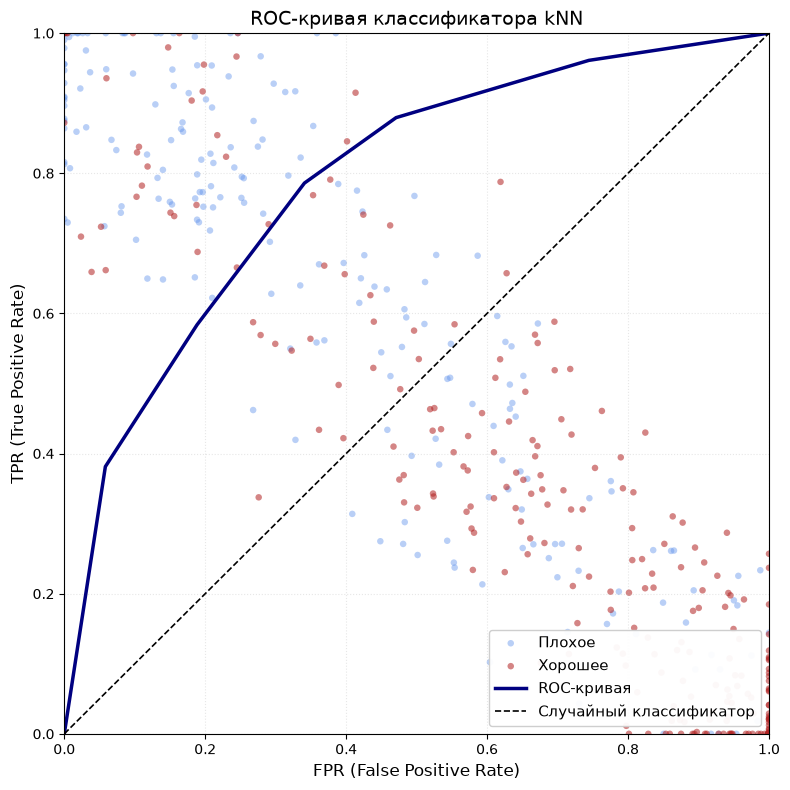

AUC-ROC = 0.7889


In [ ]:
y_proba = knn.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_proba, pos_label=1)
auc_score = roc_auc_score(y_test, y_proba)
fig, ax = plt.subplots(figsize=(8, 8))

np.random.seed(42)
jitter = 0.10

x_pts = np.clip(y_proba + np.random.normal(0, jitter, len(y_proba)), 0, 1)
y_pts = np.clip(1 - y_proba + np.random.normal(0, jitter, len(y_proba)), 0, 1)

mask_neg = (y_test == -1)
mask_pos = (y_test == 1)
ax.scatter(x_pts[mask_neg], y_pts[mask_neg],
           c='cornflowerblue', alpha=0.45, s=22,
           edgecolors='none', label='Плохое')
ax.scatter(x_pts[mask_pos], y_pts[mask_pos],
           c='firebrick', alpha=0.55, s=22,
           edgecolors='none', label='Хорошее')
# ROC-кривая
ax.plot(fpr, tpr, color='navy', lw=2.5,
        label=f'ROC-кривая')
ax.plot([0, 1], [0, 1], color='black', lw=1.2, linestyle='--',
        label='Случайный классификатор')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.0])
ax.set_xlabel('FPR (False Positive Rate)', fontsize=12)
ax.set_ylabel('TPR (True Positive Rate)', fontsize=12)
ax.set_title('ROC-кривая классификатора kNN', fontsize=14)
ax.grid(True, alpha=0.3, linestyle=':')
ax.legend(loc='lower right', fontsize=11, framealpha=0.95)

plt.tight_layout()
plt.show()

print(f"AUC-ROC = {auc_score:.4f}")

### Выводы по полученным результатам

1. **Предобработка и масштабирование признаков**: Поскольку метод $k$ ближайших соседей ($k$NN) является метрическим алгоритмом и опирается на вычисление евклидова расстояния между объектами, предварительная стандартизация (`StandardScaler`, $\mu=0, \sigma=1$) критически важна — без нее признаки с большими абсолютными значениями (`total sulfur dioxide`, `free sulfur dioxide`) подавляли бы вклад остальных физико-химических показателей.
2. **Анализ матрицы путаницы (Confusion Matrix)**:
   - На тестовой выборке из $480$ образцов ($30\%$ от $1599$ записей) классификатор `KNeighborsClassifier(n_neighbors=5)` верно классифицировал **$155$ плохих вин ($TN$)** и **$192$ хороших вина ($TP$)**.
   - Ошибки первого рода ($FP = 68$ — «плохое» вино названо «хорошим») и второго рода ($FN = 65$ — «хорошее» вино названо «плохим») сбалансированы.
3. **Итоговые метрики качества**:
   - Точность (`Accuracy`) составила **$72.29\%$** ($0.7229$).
   - Для положительного класса («Хорошее вино», метка $+1$): `Precision` $= 0.7385$, `Recall` $= 0.7471$, мера `F1-score` $= 0.7427$, специфичность (`Specificity`) $= 0.6951$.
   - Площадь под ROC-кривой **`AUC-ROC = 0.7931`** существенно превышает уровень случайного гадания ($0.5$), что подтверждает хорошую разделяющую способность модели $k$NN для определения качества красного вина по физико-химическим параметрам.